In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import time
from codecarbon import EmissionsTracker, OfflineEmissionsTracker
import re
from transformers import BertModel, BertTokenizer
import torch
from scipy.stats import skew
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering
from tabulate import tabulate
import matplotlib.pyplot as plt
import torch.nn.functional as F

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import re


NOTEBOOK_DIR = Path.cwd()
if (NOTEBOOK_DIR / "ECtHR" / "data" / "ecthr_cases_raw").exists():
    NOTEBOOK_DIR = NOTEBOOK_DIR / "ECtHR"
DATA_DIR = NOTEBOOK_DIR / "data" / "ecthr_cases_raw"
if not (DATA_DIR / "train.jsonl").exists():
    raise FileNotFoundError("Open this notebook in GR or ECtHR; raw JSONL files are required.")
ROOT = NOTEBOOK_DIR.parent

train_raw = pd.read_json(
    DATA_DIR / "train.jsonl",
    lines=True,
)

validation_raw = pd.read_json(
    DATA_DIR / "dev.jsonl",
    lines=True,
)

test_raw = pd.read_json(
    DATA_DIR / "test.jsonl",
    lines=True,
)

train_raw["split"] = "train"
validation_raw["split"] = "validation"
test_raw["split"] = "test"

raw_df = pd.concat(
    [
        train_raw,
        validation_raw,
        test_raw,
    ],
    ignore_index=True,
)

print("Train:", train_raw.shape)
print(
    "Validation:",
    validation_raw.shape,
)
print("Test:", test_raw.shape)
print("Combined:", raw_df.shape)

Train: (9000, 13)
Validation: (1000, 13)
Test: (1000, 13)
Combined: (11000, 13)


In [3]:
def normalize_labels(value):
    if isinstance(
        value,
        (
            list,
            tuple,
            np.ndarray,
        ),
    ):
        return sorted({
            str(label)
            for label in value
            if pd.notna(label)
        })

    if pd.isna(value):
        return []

    return [str(value)]


def combine_facts(value):
    if isinstance(
        value,
        (
            list,
            tuple,
            np.ndarray,
        ),
    ):
        text = " ".join(
            str(sentence)
            for sentence in value
            if pd.notna(sentence)
        )
    elif pd.isna(value):
        text = ""
    else:
        text = str(value)

    # Preserve punctuation.
    # Only normalize whitespace.
    text = text.replace(
        "\u00a0",
        " ",
    )

    text = re.sub(
        r"\s+",
        " ",
        text,
    )

    return text.strip()

In [4]:
ecthr_df = pd.DataFrame({
    "document_id": (
        raw_df["case_id"]
        .astype(str)
    ),

    "training_text": (
        raw_df["facts"]
        .apply(combine_facts)
    ),

    # Actual 29-label targets
    "target_labels": (
        raw_df[
            "violated_articles"
        ]
        .apply(normalize_labels)
    ),

    "split": (
        raw_df["split"]
        .replace({
            "dev": "validation",
        })
    ),
})

In [5]:
NO_VIOLATION_LABEL = (
    "__NO_VIOLATION__"
)

ecthr_df["labels"] = (
    ecthr_df[
        "target_labels"
    ]
    .apply(
        lambda labels: (
            labels
            if len(labels) > 0
            else [
                NO_VIOLATION_LABEL
            ]
        )
    )
)

In [6]:
ecthr_df = (
    ecthr_df[
        ecthr_df[
            "training_text"
        ]
        .str.len()
        .gt(0)
    ]
    .drop_duplicates(
        subset=[
            "document_id"
        ],
        keep="first",
    )
    .reset_index(drop=True)
)

ecthr_df["char_length"] = (
    ecthr_df[
        "training_text"
    ]
    .str.len()
)

ecthr_df["length"] = (
    ecthr_df[
        "training_text"
    ]
    .str.split()
    .str.len()
)

In [7]:
actual_label_names = sorted(
    ecthr_df[
        "target_labels"
    ]
    .explode()
    .dropna()
    .unique()
)

analysis_label_names = sorted(
    ecthr_df["labels"]
    .explode()
    .dropna()
    .unique()
)

print(
    "Dataset shape:",
    ecthr_df.shape,
)

print(
    "Actual labels:",
    len(actual_label_names),
)

print(actual_label_names)

print(
    "Analysis labels:",
    len(analysis_label_names),
)

print(
    "No-violation documents:",
    ecthr_df[
        "target_labels"
    ]
    .apply(len)
    .eq(0)
    .sum(),
)

print(
    "Minimum word count:",
    ecthr_df["length"].min(),
)

print(
    "Average word count:",
    ecthr_df["length"].mean(),
)

print(
    "Maximum word count:",
    ecthr_df["length"].max(),
)

print("\nSplit counts:")
print(
    ecthr_df[
        "split"
    ].value_counts()
)

display(
    ecthr_df[
        [
            "document_id",
            "training_text",
            "target_labels",
            "labels",
            "split",
            "length",
        ]
    ].head()
)

Dataset shape: (11000, 7)
Actual labels: 29
['10', '11', '12', '13', '14', '18', '2', '3', '34', '38', '4', '46', '5', '6', '7', '8', '9', 'P1-1', 'P1-2', 'P1-3', 'P12-1', 'P4-2', 'P4-4', 'P6-1', 'P6-3', 'P7-1', 'P7-2', 'P7-3', 'P7-4']
Analysis labels: 30
No-violation documents: 1045
Minimum word count: 69
Average word count: 1662.0804545454546
Maximum word count: 35416

Split counts:
split
train         9000
validation    1000
test          1000
Name: count, dtype: int64


,document_id,training_text,target_labels,labels,split,length
0,001-59587,11. At the beginning of the events relevant to...,[8],[8],train,6884
1,001-59591,9. The applicant is the monarch of Liechtenste...,[],[__NO_VIOLATION__],train,2758
2,001-59590,9. In June 1949 plots of agricultural land own...,[6],[6],train,1347
3,001-59588,"8. In 1991 Mr Dušan Slobodník, a research work...",[10],[10],train,3859
4,001-59589,"9. The applicant is an Italian citizen, born i...",[],[__NO_VIOLATION__],train,571


In [8]:
sampling_df = (
    ecthr_df[
        ecthr_df["split"]
        == "train"
    ]
    .copy()
    .reset_index(drop=True)
)

In [9]:
display(
    sampling_df[
        [
            "document_id",
            "training_text",
            "labels",
            "length",
        ]
    ].head()
)

,document_id,training_text,labels,length
0,001-59587,11. At the beginning of the events relevant to...,[8],6884
1,001-59591,9. The applicant is the monarch of Liechtenste...,[__NO_VIOLATION__],2758
2,001-59590,9. In June 1949 plots of agricultural land own...,[6],1347
3,001-59588,"8. In 1991 Mr Dušan Slobodník, a research work...",[10],3859
4,001-59589,"9. The applicant is an Italian citizen, born i...",[__NO_VIOLATION__],571


In [10]:
TEXT_COL = "training_text"
LABEL_COL = "labels"

SAMPLE_SIZE = 200
RANDOM_SEED = 20261027
NUM_REPETITIONS = 10
BATCH_SIZE = 64
MAX_TOKEN = 128

MODELS = [
    "google-bert/bert-base-uncased",
    "allenai/scibert_scivocab_uncased",
    "nlpaueb/legal-bert-base-uncased",
    "ahmedrachid/FinancialBERT",
    "Lianglab/PharmBERT-uncased",
    "recobo/agriculture-bert-uncased",
    "recobo/chemical-bert-uncased",
]
from datetime import datetime
import json
import pickle
if not torch.cuda.is_available():
    raise RuntimeError("CUDA unavailable: select the RTX 5080 .venv Python kernel.")
print("GPU:", torch.cuda.get_device_name(0))
torch.backends.cuda.matmul.allow_tf32 = False
OUTPUT_DIR = NOTEBOOK_DIR / "results" / ("uncertainty10_gpu_" + datetime.now().strftime("%Y%m%d_%H%M%S"))
OUTPUT_DIR.mkdir(parents=True, exist_ok=False)
print("Results directory:", OUTPUT_DIR.resolve())


GPU: NVIDIA GeForce RTX 5080
Results directory: /home/amyliu/Desktop/GR/ECtHR/results/uncertainty10_gpu_20261025_170358


In [11]:
def asymmetry_eta(x, bandwidth=None):
    """Original leave-one-out eta estimator, evaluated in float64 on CUDA.

    Row chunks limit GPU memory; strict empirical CDF handles ties exactly.
    """
    with torch.inference_mode():
        x = torch.as_tensor(np.asarray(x, dtype=float), device="cuda", dtype=torch.float64)
        x = x[~torch.isnan(x)]
        n = x.numel()
        if n < 3:
            return np.nan
        s = x.std(correction=1)
        q = torch.quantile(x, torch.tensor([0.25, 0.75], device=x.device, dtype=x.dtype))
        iqr = q[1] - q[0]
        sigma = torch.minimum(s, iqr / 1.349) if iqr.item() > 0 else s
        if torch.isclose(sigma, torch.zeros_like(sigma), rtol=1e-5, atol=1e-8).item():
            sigma = s if s.item() > 0 else x.new_tensor(1.0)
        h = x.new_tensor(bandwidth) if bandwidth is not None else 0.9 * sigma * n ** (-1 / 5)
        if h.item() <= 0:
            h = 1.06 * (s if s.item() > 0 else x.new_tensor(1.0)) * n ** (-1 / 5)
        f_hat = torch.empty_like(x)
        normalizer = (2 * np.pi) ** -0.5
        for start in range(0, n, 128):
            end = min(start + 128, n)
            kernel = (x.unsqueeze(0) - x[start:end].unsqueeze(1)) / h
            kernel.square_().mul_(-0.5).exp_().mul_(normalizer)
            kernel[torch.arange(end-start, device=x.device), torch.arange(start,end,device=x.device)] = 0
            f_hat[start:end] = kernel.sum(dim=1) / ((n - 1) * h)
        F_hat = torch.searchsorted(torch.sort(x).values, x, right=False).to(x.dtype) / (n - 1)
        if f_hat.std(correction=1).item() == 0 or F_hat.std(correction=1).item() == 0:
            return np.nan
        return (-torch.corrcoef(torch.stack((f_hat, F_hat)))[0, 1]).item()


In [12]:
def chi2_distance(dist1, dist2, bins=50, value_range=None, eps=1e-12):
    # Preserve NumPy bin edges and boundary conventions; count and reduce on GPU.
    edges = np.histogram_bin_edges(dist1, bins=bins, range=value_range)
    edges = torch.as_tensor(edges, device="cuda", dtype=torch.float64)
    def histogram(values):
        values = torch.as_tensor(np.asarray(values), device="cuda", dtype=torch.float64)
        valid = (values >= edges[0]) & (values <= edges[-1])
        indices = torch.bucketize(values[valid], edges, right=True) - 1
        indices.clamp_(max=edges.numel()-2)
        counts = torch.bincount(indices, minlength=edges.numel()-1).to(torch.float64)
        return counts / counts.sum()
    p, q = histogram(dist1), histogram(dist2)
    return (0.5 * ((p-q).square() / (p+q+eps)).sum()).item()


In [13]:
def create_cosine_similarity_matrix(embeddings):
    with torch.inference_mode():
        normalized = F.normalize(embeddings.detach().to("cuda", dtype=torch.float32), p=2, dim=1)
        return (normalized @ normalized.T).cpu().numpy()


In [14]:
from collections import defaultdict
from itertools import combinations

import numpy as np


def convert_to_label_sets(labels):
    label_sets = []

    for document_labels in labels:
        if isinstance(
            document_labels,
            str,
        ):
            label_set = {
                document_labels
            }
        else:
            label_set = set(
                document_labels
            )

        label_sets.append(
            label_set
        )

    return label_sets

In [15]:
def calculate_within_label_cosine_distribution(
    embeddings,
    labels,
    return_by_label=True,
):
    label_sets = convert_to_label_sets(
        labels
    )

    similarity_matrix = (
        create_cosine_similarity_matrix(
            embeddings
        )
    )

    all_scores = []

    scores_by_label = defaultdict(
        list
    )

    number_of_documents = len(
        label_sets
    )

    for first_index, second_index in combinations(
        range(number_of_documents),
        2,
    ):
        shared_labels = (
            label_sets[first_index]
            .intersection(
                label_sets[second_index]
            )
        )

        # Same-label means at least one
        # shared label.
        if not shared_labels:
            continue

        score = float(
            similarity_matrix[
                first_index,
                second_index,
            ]
        )

        # Add once to the overall distribution,
        # regardless of how many labels are shared.
        all_scores.append(
            score
        )

        # Per-label diagnostic data.
        # The score can appear in multiple label
        # groups here, but not in all_scores.
        for label in shared_labels:
            scores_by_label[
                label
            ].append(score)

    all_scores = np.asarray(
        all_scores,
        dtype=float,
    )

    if len(all_scores) == 0:
        raise ValueError(
            "No within-label document "
            "pairs were found."
        )

    scores_by_label = {
        label: np.asarray(
            label_scores,
            dtype=float,
        )
        for label, label_scores
        in sorted(
            scores_by_label.items()
        )
    }

    print(
        "Total unique within-label "
        "document pairs:",
        len(all_scores),
    )

    if return_by_label:
        return (
            all_scores,
            scores_by_label,
        )

    return all_scores

In [16]:
def calculate_between_label_cosine_distribution(
    embeddings,
    labels,
    return_by_label_pair=True,
):
    label_sets = convert_to_label_sets(
        labels
    )

    similarity_matrix = (
        create_cosine_similarity_matrix(
            embeddings
        )
    )

    all_scores = []

    scores_by_label_pair = defaultdict(
        list
    )

    number_of_documents = len(
        label_sets
    )

    for first_index, second_index in combinations(
        range(number_of_documents),
        2,
    ):
        first_label_set = (
            label_sets[first_index]
        )

        second_label_set = (
            label_sets[second_index]
        )

        # Different-label means no shared labels.
        if not first_label_set.isdisjoint(
            second_label_set
        ):
            continue

        score = float(
            similarity_matrix[
                first_index,
                second_index,
            ]
        )

        # Add each document pair exactly once.
        all_scores.append(
            score
        )

        # Store the full label-set pair only
        # for diagnostic purposes.
        first_key = tuple(
            sorted(first_label_set)
        )

        second_key = tuple(
            sorted(second_label_set)
        )

        label_set_pair = tuple(
            sorted(
                (
                    first_key,
                    second_key,
                )
            )
        )

        scores_by_label_pair[
            label_set_pair
        ].append(score)

    all_scores = np.asarray(
        all_scores,
        dtype=float,
    )

    if len(all_scores) == 0:
        raise ValueError(
            "No between-label document "
            "pairs were found."
        )

    scores_by_label_pair = {
        label_pair: np.asarray(
            pair_scores,
            dtype=float,
        )
        for label_pair, pair_scores
        in scores_by_label_pair.items()
    }

    print(
        "Number of label-set pair types:",
        len(scores_by_label_pair),
    )

    print(
        "Total unique between-label "
        "document pairs:",
        len(all_scores),
    )

    if return_by_label_pair:
        return (
            all_scores,
            scores_by_label_pair,
        )

    return all_scores

In [17]:
def prepare_sampling_dataframe(
    training_df,
):
    result = training_df[
        [
            "document_id",
            TEXT_COL,
            LABEL_COL,
        ]
    ].copy()

    # Remove missing essential values
    result = result.dropna(
        subset=[
            "document_id",
            TEXT_COL,
            LABEL_COL,
        ]
    )

    # Remove empty text
    result = result[
        result[TEXT_COL]
        .astype(str)
        .str.strip()
        .ne("")
    ].copy()

    # One row per document
    result = result.drop_duplicates(
        subset=["document_id"],
        keep="first",
    )

    # Character count: descriptive only
    result["char_length"] = (
        result[TEXT_COL]
        .str.len()
    )

    # Word count: used for quantile sampling
    result["length"] = (
        result[TEXT_COL]
        .str.split()
        .str.len()
    )

    result = result.reset_index(
        drop=True
    )

    print(
        "Shape:",
        result.shape,
    )

    print(
        "Minimum word count:",
        result["length"].min(),
    )

    print(
        "Average word count:",
        result["length"].mean(),
    )

    print(
        "Maximum word count:",
        result["length"].max(),
    )

    print(
        "Number of labels:",
        result[LABEL_COL]
        .explode()
        .nunique(),
    )

    return result

In [18]:
sampling_df = (
    prepare_sampling_dataframe(
        sampling_df
    )
)

Shape: (9000, 5)
Minimum word count: 69
Average word count: 1619.237111111111
Maximum word count: 35416
Number of labels: 30


In [19]:
def sample_from_length_groups(
    df,
    sample_size=200,
    num_quantiles=100,
    random_seed=42,
    text_col="training_text",
):
    sampling_pool = (
        df.copy()
        .reset_index(drop=True)
    )

    if sample_size > len(sampling_pool):
        raise ValueError(
            f"sample_size={sample_size} exceeds "
            f"dataset size={len(sampling_pool)}"
        )

    # Calculate word count if it does not exist
    if "length" not in sampling_pool.columns:
        sampling_pool["length"] = (
            sampling_pool[text_col]
            .astype(str)
            .str.split()
            .str.len()
        )

    # The actual number of groups cannot exceed:
    # 1. requested quantiles
    # 2. sample size
    # 3. number of unique text lengths
    effective_quantiles = min(
        num_quantiles,
        sample_size,
        sampling_pool["length"].nunique(),
    )

    # Create length groups from the whole dataset
    sampling_pool["_length_group"] = pd.qcut(
        sampling_pool["length"],
        q=effective_quantiles,
        labels=False,
        duplicates="drop",
    )

    number_of_groups = (
        sampling_pool["_length_group"]
        .nunique()
    )

    samples_per_group = (
        sample_size // number_of_groups
    )

    sampled_parts = []

    # Sample approximately the same number
    # from every length group
    for group_number, group_df in (
        sampling_pool.groupby(
            "_length_group",
            observed=True,
        )
    ):
        number_to_sample = min(
            samples_per_group,
            len(group_df),
        )

        sampled_part = group_df.sample(
            n=number_to_sample,
            random_state=(
                random_seed
                + int(group_number)
            ),
        )

        sampled_parts.append(
            sampled_part
        )

    sampled_df = pd.concat(
        sampled_parts,
        axis=0,
    )

    # Fill remaining positions if qcut produced
    # fewer groups or some groups were too small
    remaining_count = (
        sample_size - len(sampled_df)
    )

    if remaining_count > 0:
        remaining_pool = (
            sampling_pool.drop(
                index=sampled_df.index
            )
        )

        additional_samples = (
            remaining_pool.sample(
                n=remaining_count,
                random_state=random_seed,
            )
        )

        sampled_df = pd.concat(
            [
                sampled_df,
                additional_samples,
            ],
            axis=0,
        )

    # Shuffle the final sample
    sampled_df = (
        sampled_df
        .sample(
            frac=1,
            random_state=random_seed,
        )
        .drop(
            columns=["_length_group"]
        )
        .reset_index(drop=True)
    )

    print(
        "Original dataset size:",
        len(sampling_pool),
    )
    print(
        "Actual sample size:",
        len(sampled_df),
    )
    print(
        "Minimum word count:",
        sampled_df["length"].min(),
    )
    print(
        "Average word count:",
        sampled_df["length"].mean(),
    )
    print(
        "Maximum word count:",
        sampled_df["length"].max(),
    )
    print(
        "Number of represented labels:",
        sampled_df["labels"]
        .explode()
        .nunique(),
    )

    return sampled_df

In [20]:
sampled_df = sample_from_length_groups(
    df=sampling_df,
    sample_size=SAMPLE_SIZE,
    num_quantiles=100,
    random_seed=RANDOM_SEED,
    text_col=TEXT_COL,
)

Original dataset size: 9000
Actual sample size: 200
Minimum word count: 96
Average word count: 1577.2
Maximum word count: 10238
Number of represented labels: 15


In [21]:
from transformers import (
    AutoTokenizer,
    AutoModel,
)


def compute_embeddings(
    texts,
    model_name,
    batch_size=64,
    max_token=128,
):
    # Auto classes support all seven model checkpoints
    tokenizer = AutoTokenizer.from_pretrained(
        model_name,
        use_fast=True,
    )

    model = AutoModel.from_pretrained(
        model_name,
    )

    device = torch.device(
        "cuda"
        if torch.cuda.is_available()
        else "cpu"
    )

    model = model.to(device)
    model.eval()

    all_embeddings = []

    for start_index in range(
        0,
        len(texts),
        batch_size,
    ):
        batch_texts = texts[
            start_index:
            start_index + batch_size
        ]

        inputs = tokenizer(
            batch_texts,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=max_token,
        )

        inputs = {
            key: value.to(device)
            for key, value in inputs.items()
        }

        with torch.inference_mode():
            outputs = model(**inputs)

            token_embeddings = (
                outputs.last_hidden_state
            )

            # Shape:
            # attention_mask:
            # [batch_size, sequence_length]
            #
            # expanded_mask:
            # [batch_size, sequence_length, 1]
            expanded_mask = (
                inputs["attention_mask"]
                .unsqueeze(-1)
                .to(token_embeddings.dtype)
            )

            # Sum only real-token embeddings
            summed_embeddings = (
                token_embeddings
                * expanded_mask
            ).sum(dim=1)

            # Number of real tokens in each text
            valid_token_counts = (
                expanded_mask
                .sum(dim=1)
                .clamp(min=1e-9)
            )

            # Masked mean pooling
            batch_embeddings = (
                summed_embeddings
                / valid_token_counts
            )

        all_embeddings.append(
            batch_embeddings.cpu()
        )

    embeddings = torch.cat(
        all_embeddings,
        dim=0,
    )

    print(
        "Model:",
        model_name,
    )
    print(
        "Device:",
        device,
    )
    print(
        "Embedding shape:",
        tuple(embeddings.shape),
    )

    return embeddings

In [22]:
def bootstrap_chi2_from_existing_scores(
    same_scores,
    diff_label,
    n_bootstrap=1000,
    random_seed=42,
    bins=50,
    value_range=(-1, 1),
    eta_bandwidth=None
):

    rng = np.random.default_rng(random_seed)

    same_scores = np.asarray(same_scores)
    target_size = len(same_scores)

    # same-label statistics, fixed across bootstrap
    same_mean = torch.as_tensor(same_scores, device="cuda", dtype=torch.float64).mean().item()
    same_eta = asymmetry_eta(same_scores, bandwidth=eta_bandwidth)
    same_abs_eta = abs(same_eta)

    label_pairs = list(diff_label.keys())
    n_pair_types = len(label_pairs)

    base_n = target_size // n_pair_types
    remainder = target_size % n_pair_types

    bootstrap_rows = []

    print("Same-label target size:", target_size)
    print("Different-label pair types:", n_pair_types)
    print("Base sample per diff-label pair:", base_n)

    for b in range(n_bootstrap):
        sampled_diff_scores = []

        for k, pair in enumerate(label_pairs):
            # already-computed cosine similarity scores for this label pair
            cosine_scores_for_this_pair = np.asarray(diff_label[pair])

            n_sample = base_n + (1 if k < remainder else 0)

            sampled_cosine_scores = rng.choice(
                cosine_scores_for_this_pair,
                size=n_sample,
                replace=True
            )

            sampled_diff_scores.extend(sampled_cosine_scores)

        sampled_diff_scores = np.asarray(sampled_diff_scores)

        # chi-square distance between same-label and bootstrapped diff-label distributions
        chi2_dist = chi2_distance(
            dist1=same_scores,
            dist2=sampled_diff_scores,
            bins=bins,
            value_range=value_range
        )

        # bootstrap diff-label statistics
        diff_mean = torch.as_tensor(sampled_diff_scores, device="cuda", dtype=torch.float64).mean().item()
        diff_eta = asymmetry_eta(sampled_diff_scores, bandwidth=eta_bandwidth)
        diff_abs_eta = abs(diff_eta)

        mean_gap = same_mean - diff_mean
        abs_mean_gap = abs(mean_gap)

        eta_gap = same_eta - diff_eta
        abs_eta_gap = abs(eta_gap)

        chi2_result = {
            "bootstrap": b + 1,

            # same-label statistics, fixed
            "same_mean": same_mean,
            "same_eta": same_eta,
            "same_abs_eta": same_abs_eta,

            # bootstrapped diff-label statistics
            "diff_mean": diff_mean,
            "diff_eta": diff_eta,
            "diff_abs_eta": diff_abs_eta,

            # gaps
            "mean_gap": mean_gap,
            "abs_mean_gap": abs_mean_gap,
            "eta_gap": eta_gap,
            "abs_eta_gap": abs_eta_gap,

            # distribution distance
            "chi2_distance": chi2_dist,

            # pair numbers
            "same_n_pairs": len(same_scores),
            "diff_n_pairs": len(sampled_diff_scores)
        }

        bootstrap_rows.append(chi2_result)
        if (b + 1) % 100 == 0:
            print(f"Bootstrap {b + 1}/{n_bootstrap}", flush=True)

    bootstrap_chi2_df = pd.DataFrame(bootstrap_rows)

    chi2_summary = {
        # same-label statistics
        "same_mean": same_mean,
        "same_eta": same_eta,
        "same_abs_eta": same_abs_eta,

        # averaged bootstrapped diff-label statistics
        "diff_mean": bootstrap_chi2_df["diff_mean"].mean(),
        "diff_mean_std": bootstrap_chi2_df["diff_mean"].std(),

        "diff_eta": bootstrap_chi2_df["diff_eta"].mean(),
        "diff_eta_std": bootstrap_chi2_df["diff_eta"].std(),
        "diff_abs_eta": bootstrap_chi2_df["diff_abs_eta"].mean(),

        # averaged gaps
        "mean_gap": bootstrap_chi2_df["mean_gap"].mean(),
        "mean_gap_std": bootstrap_chi2_df["mean_gap"].std(),
        "abs_mean_gap": bootstrap_chi2_df["abs_mean_gap"].mean(),

        "eta_gap": bootstrap_chi2_df["eta_gap"].mean(),
        "eta_gap_std": bootstrap_chi2_df["eta_gap"].std(),
        "abs_eta_gap": bootstrap_chi2_df["abs_eta_gap"].mean(),

        # averaged chi-square distance
        "chi2_distance": bootstrap_chi2_df["chi2_distance"].mean(),
        "chi2_distance_std": bootstrap_chi2_df["chi2_distance"].std(),

        # metadata
        "same_n_pairs": len(same_scores),
        "diff_n_pairs": bootstrap_chi2_df["diff_n_pairs"].mean(),
        "n_bootstrap": n_bootstrap,
        "bins": bins,
        "value_range": value_range
    }

    return bootstrap_chi2_df, chi2_summary

In [23]:
def run_one_model_chi2_bootstrap(
    sampled_df,
    model_name,
    batch_size=64,
    max_token=128,
    text_col="training_text",
    label_col="labels",
    n_bootstrap=1000,
    random_seed=42,
    bins=50,
    value_range=(-1, 1),
    eta_bandwidth=None,
):
    print(
        f"\nRunning model: {model_name}"
    )

    # Ohsumed text and multi-label columns
    texts = (
        sampled_df[text_col]
        .astype(str)
        .tolist()
    )

    # Keep labels as list of lists:
    # [["C01"], ["C02", "C03"], ...]
    labels = (
        sampled_df[label_col]
        .tolist()
    )

    # 1. Compute pretrained embeddings once
    embeddings = compute_embeddings(
        texts=texts,
        model_name=model_name,
        batch_size=batch_size,
        max_token=max_token,
    )

    # 2. Same-label cosine distribution
    same_scores, scores_by_label = (
        calculate_within_label_cosine_distribution(
            embeddings=embeddings,
            labels=labels,
            return_by_label=True,
        )
    )

    # 3. Different-label cosine distribution
    diff_scores_original, diff_label = (
        calculate_between_label_cosine_distribution(
            embeddings=embeddings,
            labels=labels,
            return_by_label_pair=True,
        )
    )

    # 4. Bootstrap the already-computed
    # different-label cosine scores
    (
        bootstrap_chi2_df,
        chi2_summary,
    ) = bootstrap_chi2_from_existing_scores(
        same_scores=same_scores,
        diff_label=diff_label,
        n_bootstrap=n_bootstrap,
        random_seed=random_seed,
        bins=bins,
        value_range=value_range,
        eta_bandwidth=eta_bandwidth,
    )

    # 5. Create one summary row for this model
    summary = {
        "model": model_name,

        # Same-label distribution
        "same_mean":
            chi2_summary["same_mean"],

        "same_eta":
            chi2_summary["same_eta"],

        "same_abs_eta":
            chi2_summary["same_abs_eta"],

        "same_n_pairs":
            chi2_summary["same_n_pairs"],

        # Bootstrapped different-label distribution
        "diff_mean":
            chi2_summary["diff_mean"],

        "diff_mean_std":
            chi2_summary["diff_mean_std"],

        "diff_eta":
            chi2_summary["diff_eta"],

        "diff_eta_std":
            chi2_summary["diff_eta_std"],

        "diff_abs_eta":
            chi2_summary["diff_abs_eta"],

        "diff_n_pairs":
            chi2_summary["diff_n_pairs"],

        # Same–different gaps
        "mean_gap":
            chi2_summary["mean_gap"],

        "mean_gap_std":
            chi2_summary["mean_gap_std"],

        "abs_mean_gap":
            chi2_summary["abs_mean_gap"],

        "eta_gap":
            chi2_summary["eta_gap"],

        "eta_gap_std":
            chi2_summary["eta_gap_std"],

        "abs_eta_gap":
            chi2_summary["abs_eta_gap"],

        # Distribution distance
        "chi2_distance":
            chi2_summary["chi2_distance"],

        "chi2_distance_std":
            chi2_summary[
                "chi2_distance_std"
            ],

        # Original pair count before bootstrap
        "diff_original_n_pairs":
            len(diff_scores_original),

        # Experimental settings
        "n_bootstrap": n_bootstrap,
        "bins": bins,
        "value_range": value_range,
        "batch_size": batch_size,
        "max_token": max_token,
        "random_seed": random_seed,
    }

    print("\nSummary:")
    print(
        "Same mean:",
        summary["same_mean"],
    )
    print(
        "Different mean:",
        summary["diff_mean"],
    )
    print(
        "Mean gap:",
        summary["mean_gap"],
    )
    print(
        "Same eta:",
        summary["same_eta"],
    )
    print(
        "Different eta:",
        summary["diff_eta"],
    )
    print(
        "Different |eta|:",
        summary["diff_abs_eta"],
    )
    print(
        "Eta gap:",
        summary["eta_gap"],
    )
    print(
        "Chi-square distance:",
        summary["chi2_distance"],
    )
    print(
        "Chi-square bootstrap std:",
        summary["chi2_distance_std"],
    )

    return {
        # Final row used for model comparison
        "summary": summary,

        # Original cosine distributions
        "same_scores": same_scores,
        "diff_scores_original":
            diff_scores_original,

        # Scores grouped by labels
        "scores_by_label":
            scores_by_label,
        "diff_label":
            diff_label,

        # All 1000 bootstrap metric rows
        "bootstrap_chi2_df":
            bootstrap_chi2_df,

        # Bootstrap summary dictionary
        "chi2_summary":
            chi2_summary,

        # Model outputs and corresponding data
        "embeddings": embeddings,
        "labels": labels,
        "document_ids": (
            sampled_df["document_id"]
            .tolist()
        ),

        # Preserve the exact sampled data
        "sampled_df":
            sampled_df.copy(),
    }

In [24]:
def metric_collect(
    grouped_df,
    sample_size=200,
    num_quantiles=100,
    num_repetitions=10,
    models=None,
    batch_size=64,
    max_token=128,
    text_col=TEXT_COL,
    label_col=LABEL_COL,
    n_bootstrap=1000,
    bins=50,
    value_range=(-1, 1),
    eta_bandwidth=None,
    master_seed=42,
    output_dir=None,
):
    if models is None:
        models = MODELS

    summary_results = []
    full_results = {}

    # Produce reproducible but different seeds
    # for different repetitions
    seed_generator = (
        np.random.default_rng(
            master_seed
        )
    )

    repetition_seeds = (
        seed_generator.integers(
            low=0,
            high=2**32 - 1,
            size=num_repetitions,
            dtype=np.uint32,
        )
    )

    if output_dir is not None:
        output_dir = Path(output_dir)
        output_dir.mkdir(parents=True, exist_ok=True)
        (output_dir / "run_config.json").write_text(json.dumps({
            "statistics_device": "cuda", "dataset": "ECtHR",
            "master_seed": master_seed, "repetition_seeds": repetition_seeds.tolist(),
            "num_repetitions": num_repetitions, "models": models,
            "sample_size_requested": sample_size, "num_quantiles": num_quantiles,
            "batch_size": batch_size, "max_token": max_token,
            "n_bootstrap": n_bootstrap, "bins": bins, "value_range": value_range,
            "eta_bandwidth": eta_bandwidth, "text_col": text_col, "label_col": label_col,
        }, indent=2))

    for repetition in range(
        num_repetitions
    ):
        print(
            "================================"
            "================="
        )
        print(
            f"Repetition "
            f"{repetition + 1}/"
            f"{num_repetitions}"
        )

        repetition_seed = int(
            repetition_seeds[repetition]
        )

        print(
            "Repetition seed:",
            repetition_seed,
        )

        # 1. Draw one length-stratified sample
        sampled_df = (
            sample_from_length_groups(
                df=grouped_df,
                sample_size=sample_size,
                num_quantiles=(
                    num_quantiles
                ),
                random_seed=(
                    repetition_seed
                ),
                text_col=text_col,
            )
        )

        print(
            "Actual sample size:",
            len(sampled_df),
        )

        if output_dir is not None:
            sampled_df.to_csv(output_dir / f"sample_{repetition + 1:02d}.csv", index=False)

        # Correct multi-label counting
        label_counts = (
            sampled_df[label_col]
            .explode()
            .value_counts()
            .sort_index()
        )

        print("Label counts:")
        print(label_counts)

        print(
            "Number of represented labels:",
            len(label_counts),
        )

        # 2. Every model uses exactly the same
        # sample in this repetition
        for model_name in models:
            result = (
                run_one_model_chi2_bootstrap(
                    sampled_df=sampled_df,
                    model_name=model_name,
                    batch_size=batch_size,
                    max_token=max_token,
                    text_col=text_col,
                    label_col=label_col,
                    n_bootstrap=n_bootstrap,
                    random_seed=(
                        repetition_seed
                    ),
                    bins=bins,
                    value_range=(
                        value_range
                    ),
                    eta_bandwidth=(
                        eta_bandwidth
                    ),
                )
            )

            summary = (
                result["summary"].copy()
            )

            summary["repetition"] = (
                repetition + 1
            )

            summary["random_seed"] = (
                repetition_seed
            )

            summary["sample_size"] = (
                sample_size
            )

            summary[
                "num_quantiles"
            ] = num_quantiles

            summary[
                "represented_labels"
            ] = len(label_counts)

            summary["actual_sample_size"] = len(sampled_df)
            summary_results.append(
                summary
            )

            full_results[
                (
                    repetition + 1,
                    model_name,
                )
            ] = result

            if output_dir is not None:
                model_file = model_name.replace("/", "__")
                with (output_dir / f"rep_{repetition + 1:02d}_{model_file}.pkl").open("wb") as handle:
                    pickle.dump(result, handle, protocol=pickle.HIGHEST_PROTOCOL)
                pd.DataFrame(summary_results).to_csv(output_dir / "summary_per_run.csv", index=False)
                print(f"Saved {len(summary_results)}/{num_repetitions * len(models)} model runs", flush=True)

    summary_df = pd.DataFrame(
        summary_results
    )

    return {
        "summary_df": summary_df,
        "full_results": full_results,
        "repetition_seeds": (
            repetition_seeds.tolist()
        ),
    }

In [25]:
results = metric_collect(
    grouped_df=sampling_df,
    sample_size=SAMPLE_SIZE,
    num_quantiles=100,
    num_repetitions=NUM_REPETITIONS,
    models=MODELS,
    batch_size=BATCH_SIZE,
    max_token=MAX_TOKEN,
    text_col=TEXT_COL,
    label_col=LABEL_COL,
    n_bootstrap=1000,
    bins=50,
    value_range=(-1, 1),
    eta_bandwidth=None,
    master_seed=RANDOM_SEED,
    output_dir=OUTPUT_DIR,
)

Repetition 1/10
Repetition seed: 3132697953
Original dataset size: 9000
Actual sample size: 200
Minimum word count: 111
Average word count: 1582.34
Maximum word count: 10914
Number of represented labels: 15
Actual sample size: 200
Label counts:
labels
10                    4
11                    3
13                   20
14                    4
2                     7
3                    25
38                    2
5                    17
6                   114
8                    21
9                     1
P1-1                 45
P1-3                  1
P7-1                  1
__NO_VIOLATION__     16
Name: count, dtype: int64
Number of represented labels: 15

Running model: google-bert/bert-base-uncased


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model: google-bert/bert-base-uncased
Device: cuda
Embedding shape: (200, 768)
Total unique within-label document pairs: 7837
Number of label-set pair types: 318
Total unique between-label document pairs: 12063
Same-label target size: 7837
Different-label pair types: 318
Base sample per diff-label pair: 24
Bootstrap 100/1000
Bootstrap 200/1000
Bootstrap 300/1000
Bootstrap 400/1000
Bootstrap 500/1000
Bootstrap 600/1000
Bootstrap 700/1000
Bootstrap 800/1000
Bootstrap 900/1000
Bootstrap 1000/1000

Summary:
Same mean: 0.8631898575296385
Different mean: 0.836903288382983
Mean gap: 0.026286569146655437
Same eta: -0.46720657484073114
Different eta: -0.40542068006192167
Different |eta|: 0.40542068006192167
Eta gap: -0.06178589477880948
Chi-square distance: 0.06612258744063303
Chi-square bootstrap std: 0.0018558772068380837
Saved 1/70 model runs

Running model: allenai/scibert_scivocab_uncased


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: allenai/scibert_scivocab_uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


... (201 outputs left out)

Model: recobo/agriculture-bert-uncased
Device: cuda
Embedding shape: (200, 768)
Total unique within-label document pairs: 7271
Number of label-set pair types: 496
Total unique between-label document pairs: 12629
Same-label target size: 7271
Different-label pair types: 496
Base sample per diff-label pair: 14
Bootstrap 100/1000
Bootstrap 200/1000
Bootstrap 300/1000
Bootstrap 400/1000
Bootstrap 500/1000
Bootstrap 600/1000
Bootstrap 700/1000
Bootstrap 800/1000
Bootstrap 900/1000
Bootstrap 1000/1000

Summary:
Same mean: 0.9162966649825135
Different mean: 0.9089909204272895
Mean gap: 0.007305744555224024
Same eta: -0.42911921347467763
Different eta: -0.4834824226589193
Different |eta|: 0.4834824226589193
Eta gap: 0.054363209184241666
Chi-square distance: 0.02203746643858612
Chi-square bootstrap std: 0.001205679488010503
Saved 69/70 model runs

Running model: recobo/chemical-bert-uncased


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

BertModel LOAD REPORT from: recobo/chemical-bert-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
bert.embeddings.position_ids               | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
pooler.dense.bias                          | MISSING    | 
pooler.dense.weight                        | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model: recobo/chemical-bert-uncased
Device: cuda
Embedding shape: (200, 768)
Total unique within-label document pairs: 7271
Number of label-set pair types: 496
Total unique between-label document pairs: 12629
Same-label target size: 7271
Different-label pair types: 496
Base sample per diff-label pair: 14
Bootstrap 100/1000
Bootstrap 200/1000
Bootstrap 300/1000
Bootstrap 400/1000
Bootstrap 500/1000
Bootstrap 600/1000
Bootstrap 700/1000
Bootstrap 800/1000
Bootstrap 900/1000
Bootstrap 1000/1000

Summary:
Same mean: 0.9453074006590976
Different mean: 0.9449429938121635
Mean gap: 0.00036440684693402157
Same eta: -0.6672895704746948
Different eta: -0.6786478988378358
Different |eta|: 0.6786478988378358
Eta gap: 0.011358328363141015
Chi-square distance: 0.012543773958701617
Chi-square bootstrap std: 0.000965852616712154
Saved 70/70 model runs


In [26]:
summary_df = results[
    "summary_df"
]

display(summary_df)

,model,same_mean,same_eta,same_abs_eta,same_n_pairs,diff_mean,diff_mean_std,diff_eta,diff_eta_std,diff_abs_eta,...,bins,value_range,batch_size,max_token,random_seed,repetition,sample_size,num_quantiles,represented_labels,actual_sample_size
0,google-bert/bert-base-uncased,0.863190,-0.467207,0.467207,7837,0.836903,0.000514,-0.405421,0.011964,0.405421,...,50,"(-1, 1)",64,128,3132697953,1,200,100,15,200
1,allenai/scibert_scivocab_uncased,0.903037,-0.448412,0.448412,7837,0.888748,0.000283,-0.396738,0.013108,0.396738,...,50,"(-1, 1)",64,128,3132697953,1,200,100,15,200
2,nlpaueb/legal-bert-base-uncased,0.895077,-0.441586,0.441586,7837,0.882576,0.000289,-0.435874,0.012592,0.435874,...,50,"(-1, 1)",64,128,3132697953,1,200,100,15,200
3,ahmedrachid/FinancialBERT,0.902628,-0.351957,0.351957,7837,0.890456,0.000253,-0.341407,0.015099,0.341407,...,50,"(-1, 1)",64,128,3132697953,1,200,100,15,200
4,Lianglab/PharmBERT-uncased,0.881499,-0.455423,0.455423,7837,0.853263,0.000482,-0.415415,0.012205,0.415415,...,50,"(-1, 1)",64,128,3132697953,1,200,100,15,200
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
65,nlpaueb/legal-bert-base-uncased,0.889670,-0.340387,0.340387,7271,0.877799,0.000252,-0.301662,0.015390,0.301662,...,50,"(-1, 1)",64,128,1646201743,10,200,100,17,200
66,ahmedrachid/FinancialBERT,0.900062,-0.437669,0.437669,7271,0.890136,0.000275,-0.562066,0.010401,0.562066,...,50,"(-1, 1)",64,128,1646201743,10,200,100,17,200
67,Lianglab/PharmBERT-uncased,0.871891,-0.461010,0.461010,7271,0.860917,0.000372,-0.569588,0.010657,0.569588,...,50,"(-1, 1)",64,128,1646201743,10,200,100,17,200
68,recobo/agriculture-bert-uncased,0.916297,-0.429119,0.429119,7271,0.908991,0.000253,-0.483482,0.010706,0.483482,...,50,"(-1, 1)",64,128,1646201743,10,200,100,17,200


In [27]:
metric_summary_df = (
    summary_df
    .groupby(
        "model",
        as_index=False,
    )
    .agg(
        # Same-label mean
        same_mean_mean=(
            "same_mean",
            "mean",
        ),
        same_mean_sampling_std=(
            "same_mean",
            "std",
        ),

        # Different-label mean
        diff_mean_mean=(
            "diff_mean",
            "mean",
        ),
        diff_mean_sampling_std=(
            "diff_mean",
            "std",
        ),

        # Average uncertainty from
        # the 1000 bootstrap runs
        diff_mean_bootstrap_std_mean=(
            "diff_mean_std",
            "mean",
        ),

        # Same-label eta
        same_eta_mean=(
            "same_eta",
            "mean",
        ),
        same_eta_sampling_std=(
            "same_eta",
            "std",
        ),

        same_abs_eta_mean=(
            "same_abs_eta",
            "mean",
        ),
        same_abs_eta_sampling_std=(
            "same_abs_eta",
            "std",
        ),

        # Different-label eta
        diff_eta_mean=(
            "diff_eta",
            "mean",
        ),
        diff_eta_sampling_std=(
            "diff_eta",
            "std",
        ),

        diff_eta_bootstrap_std_mean=(
            "diff_eta_std",
            "mean",
        ),

        diff_abs_eta_mean=(
            "diff_abs_eta",
            "mean",
        ),
        diff_abs_eta_sampling_std=(
            "diff_abs_eta",
            "std",
        ),

        # Mean separation
        mean_gap_mean=(
            "mean_gap",
            "mean",
        ),
        mean_gap_sampling_std=(
            "mean_gap",
            "std",
        ),

        mean_gap_bootstrap_std_mean=(
            "mean_gap_std",
            "mean",
        ),

        abs_mean_gap_mean=(
            "abs_mean_gap",
            "mean",
        ),
        abs_mean_gap_sampling_std=(
            "abs_mean_gap",
            "std",
        ),

        # Eta separation
        eta_gap_mean=(
            "eta_gap",
            "mean",
        ),
        eta_gap_sampling_std=(
            "eta_gap",
            "std",
        ),

        eta_gap_bootstrap_std_mean=(
            "eta_gap_std",
            "mean",
        ),

        abs_eta_gap_mean=(
            "abs_eta_gap",
            "mean",
        ),
        abs_eta_gap_sampling_std=(
            "abs_eta_gap",
            "std",
        ),

        # Chi-square distance
        chi2_distance_mean=(
            "chi2_distance",
            "mean",
        ),
        chi2_sampling_std=(
            "chi2_distance",
            "std",
        ),

        chi2_bootstrap_std_mean=(
            "chi2_distance_std",
            "mean",
        ),

        # Pair-count metadata
        same_n_pairs_mean=(
            "same_n_pairs",
            "mean",
        ),
        diff_n_pairs_mean=(
            "diff_n_pairs",
            "mean",
        ),

        represented_labels_mean=(
            "represented_labels",
            "mean",
        ),

        repetitions=(
            "repetition",
            "nunique",
        ),
    )
)

display(metric_summary_df)
metric_summary_df.to_csv(OUTPUT_DIR / "metric_summary.csv", index=False)


,model,same_mean_mean,same_mean_sampling_std,diff_mean_mean,diff_mean_sampling_std,diff_mean_bootstrap_std_mean,same_eta_mean,same_eta_sampling_std,same_abs_eta_mean,same_abs_eta_sampling_std,...,eta_gap_bootstrap_std_mean,abs_eta_gap_mean,abs_eta_gap_sampling_std,chi2_distance_mean,chi2_sampling_std,chi2_bootstrap_std_mean,same_n_pairs_mean,diff_n_pairs_mean,represented_labels_mean,repetitions
0,Lianglab/PharmBERT-uncased,0.874196,0.003006,0.856642,0.004693,0.000361,-0.404448,0.042564,0.404448,0.042564,...,0.013481,0.114909,0.068947,0.065541,0.026717,0.001988,7171.1,7171.1,16.0,10
1,ahmedrachid/FinancialBERT,0.899656,0.003182,0.888724,0.003647,0.000276,-0.413986,0.049205,0.413986,0.049205,...,0.013584,0.085575,0.070829,0.037994,0.018801,0.001595,7171.1,7171.1,16.0,10
2,allenai/scibert_scivocab_uncased,0.898282,0.003654,0.885468,0.004387,0.000322,-0.408791,0.055855,0.408791,0.055855,...,0.013793,0.124497,0.113177,0.050533,0.020700,0.001750,7171.1,7171.1,16.0,10
3,google-bert/bert-base-uncased,0.856302,0.004686,0.837303,0.002989,0.000420,-0.376911,0.050158,0.376911,0.050158,...,0.013648,0.135630,0.098389,0.059226,0.013402,0.001845,7171.1,7171.1,16.0,10
4,nlpaueb/legal-bert-base-uncased,0.889944,0.002948,0.879191,0.003583,0.000286,-0.361505,0.075080,0.361505,0.075080,...,0.014444,0.071958,0.041747,0.033478,0.012730,0.001436,7171.1,7171.1,16.0,10
5,recobo/agriculture-bert-uncased,0.918595,0.003326,0.906869,0.003389,0.000243,-0.428882,0.046893,0.428882,0.046893,...,0.013846,0.157670,0.143236,0.055381,0.025775,0.001842,7171.1,7171.1,16.0,10
6,recobo/chemical-bert-uncased,0.946639,0.003187,0.943966,0.003167,0.000227,-0.627556,0.055002,0.627556,0.055002,...,0.011337,0.091167,0.073245,0.026972,0.013061,0.001341,7171.1,7171.1,16.0,10


In [28]:
metric_ranking_df = (
    metric_summary_df[
        ["model"]
    ]
    .copy()
)

# False means descending:
# larger metric value = better rank
#
# True means ascending:
# smaller metric value = better rank
ranking_rules = {
    "same_mean_mean": False,
    "diff_mean_mean": True,
    "mean_gap_mean": False,
    "abs_mean_gap_mean": False,
    "same_abs_eta_mean": False,
    "diff_abs_eta_mean": False,
    "abs_eta_gap_mean": False,
    "chi2_distance_mean": False,
}

for metric_column, ascending in (
    ranking_rules.items()
):
    rank_column = (
        metric_column
        .removesuffix("_mean")
        + "_rank"
    )

    metric_ranking_df[
        rank_column
    ] = (
        metric_summary_df[
            metric_column
        ]
        .rank(
            ascending=ascending,
            method="min",
        )
        .astype(int)
    )

display(metric_ranking_df)

,model,same_mean_rank,diff_mean_rank,mean_gap_rank,abs_mean_gap_rank,same_abs_eta_rank,diff_abs_eta_rank,abs_eta_gap_rank,chi2_distance_rank
0,Lianglab/PharmBERT-uncased,6,2,2,2,5,3,4,1
1,ahmedrachid/FinancialBERT,3,5,5,5,3,2,6,5
2,allenai/scibert_scivocab_uncased,4,4,3,3,4,4,3,4
3,google-bert/bert-base-uncased,7,1,1,1,6,7,2,2
4,nlpaueb/legal-bert-base-uncased,5,3,6,6,7,5,7,6
5,recobo/agriculture-bert-uncased,2,6,4,4,2,6,1,3
6,recobo/chemical-bert-uncased,1,7,7,7,1,1,5,7


## Ten-sample uncertainty experiment

Each repetition draws a fresh length-stratified sample shared by all seven models.
Original ECtHR train-only sampling pool, word-length strata, 200 requested documents, 128 tokens,
and 1,000 internal bootstrap draws are retained. Exact samples and seeds are saved.
GPU calculations use the validated Financial implementation (float64 KDE in chunks).

`sampling_std` describes variation between document samples; `bootstrap_std_mean`
describes conditional variation with documents fixed. Neither is a 95% interval.
The t intervals below are approximate intervals for the **mean over repeated sampling**,
conditional on this dataset and procedure; they are not intervals for a future run or F1.
Ten repetitions are a pilot, not a guarantee of coverage.

All formulas, normalization rules and F1 targets are loaded without new grid search.
The held-out ECtHR formula is the main generalization check; the full-fit formula
has seen ECtHR and is exploratory. F1 training uncertainty is not included.


ECtHR keeps the existing multi-label overlap/disjoint pair definitions and the `__NO_VIOLATION__` analysis label. The F1 targets use the existing grid-search record; no fine-tuning is rerun.


In [29]:
from scipy.stats import rankdata, spearmanr, t
from IPython.display import display, Markdown
import seaborn as sns
MODEL_NAMES = {
    "google-bert/bert-base-uncased": "BERT",
    "allenai/scibert_scivocab_uncased": "SciBERT",
    "nlpaueb/legal-bert-base-uncased": "LegalBERT",
    "ahmedrachid/FinancialBERT": "FinancialBERT",
    "Lianglab/PharmBERT-uncased": "PharmBERT",
    "recobo/agriculture-bert-uncased": "AgricultureBERT",
    "recobo/chemical-bert-uncased": "ChemicalBERT",
}
METRICS = ["SameMean", "DffMean", "SameAbsEta", "DiffAbsEta", "Chi2Distance"]
RAW = ["same_mean", "diff_mean", "same_abs_eta", "diff_abs_eta", "chi2_distance"]
GRID = ROOT / "GridSearch" / "results_nested_five_required"
target = pd.read_csv(ROOT / "GridSearch" / "result1.csv")
target = target.loc[target.Dataset.eq("ECtHR")].set_index("ModelName").sort_index()
order = target.index.tolist()
assert len(summary_df) == 70 and summary_df.groupby("repetition").model.nunique().eq(7).all()
assert set(MODEL_NAMES.values()) == set(order)
uncertainty_rows = []
for model, g in summary_df.groupby("model"):
    for metric in RAW:
        values = g[metric].to_numpy(float)
        mean, sd = values.mean(), values.std(ddof=1)
        half = t.ppf(.975, len(values)-1) * sd / np.sqrt(len(values))
        uncertainty_rows.append(dict(model=MODEL_NAMES[model], metric=metric,
            mean=mean, sampling_std=sd, minimum=values.min(), maximum=values.max(),
            mean_t95_low=mean-half, mean_t95_high=mean+half, repetitions=len(values)))
uncertainty_df = pd.DataFrame(uncertainty_rows)
uncertainty_df.to_csv(OUTPUT_DIR / "uncertainty_summary.csv", index=False)
display(Markdown("### Five metrics: mean, sampling SD and approximate mean intervals"))
display(uncertainty_df.round(6))
# Copy sources to preserve the exact target and formulas used in this analysis.
target.to_csv(OUTPUT_DIR / "f1_target_snapshot.csv")
final = json.loads((GRID / "final_formula.json").read_text())
fold = pd.read_csv(GRID / "outer_fold_results.csv")
fold = fold.loc[fold.HeldOutDataset.eq("ECtHR") & fold.Procedure.eq("selected")].iloc[0]
coeff = pd.read_csv(GRID / "outer_coefficients.csv")
coeff = coeff.loc[coeff.HeldOutDataset.eq("ECtHR") & coeff.Procedure.eq("selected")].set_index("Metric")
CONFIGS = {
    "held_out_ECtHR": (fold.Standardization, coeff.loc[METRICS, "Coefficient"].to_numpy(float)),
    "full_fit_exploratory": (final["Standardization"], np.array([final["Coefficients"][m] for m in METRICS])),
}
# Exact existing grid-search deployment rule: normalize across seven candidate models
# within each sample. No F1 values are used to normalize or reselect weights.
def standardize(x, method):
    if method == "rank":
        z = rankdata(x, axis=0, method="average") / len(x)
        return z-z.mean(0)
    center = x.mean(0) if method == "zscore" else np.median(x, axis=0)
    spread = x.std(0) if method == "zscore" else np.median(abs(x-center), axis=0)/.6745
    return np.divide(x-center, spread, out=np.zeros_like(x), where=~np.isclose(spread, 0))
f1 = target.MacroF1.to_numpy(float)
actual = rankdata(-f1)
score_rows, round_rows, model_rows, stats_rows, contribution_rows = [], [], [], [], []
formula_manifest = {}
for procedure, (method, weights) in CONFIGS.items():
    formula_manifest[procedure] = dict(standardization=method, coefficients=dict(zip(METRICS, weights.tolist())), normalization="within each repetition across seven models; fixed rule, no tuning")
    for rep, g in summary_df.groupby("repetition"):
        g = g.assign(ModelName=g.model.map(MODEL_NAMES)).set_index("ModelName").loc[order]
        z = standardize(g[RAW].to_numpy(float), method)
        contributions = z * weights
        scores = np.round(contributions.sum(axis=1), 12)
        predicted = rankdata(-scores)
        round_rows.append(dict(procedure=procedure, repetition=int(rep),
            spearman=float(spearmanr(scores, f1).statistic),
            top1_f1_regret=float(f1.max()-f1[predicted==1].mean()),
            top3_contains_best=bool(predicted[np.argmax(f1)]<=3)))
        for j, model in enumerate(order):
            score_rows.append(dict(procedure=procedure, repetition=int(rep), model=model,
                score=scores[j], predicted_rank=predicted[j], true_rank=actual[j], MacroF1=f1[j]))
            for k, metric in enumerate(METRICS):
                contribution_rows.append(dict(procedure=procedure, repetition=int(rep),model=model,metric=metric,contribution=contributions[j,k]))
score_df, round_df = pd.DataFrame(score_rows), pd.DataFrame(round_rows)
for (procedure, model), g in score_df.groupby(["procedure", "model"]):
    model_rows.append(dict(procedure=procedure, model=model, true_rank=g.true_rank.iloc[0],
        score_mean=g.score.mean(),score_std=g.score.std(),rank_mean=g.predicted_rank.mean(),
        rank_min=g.predicted_rank.min(),rank_max=g.predicted_rank.max(),
        top1_count=int(g.predicted_rank.eq(1).sum()),top3_count=int(g.predicted_rank.le(3).sum())))
for procedure, g in round_df.groupby("procedure"):
    stats_rows.append(dict(procedure=procedure, mean_spearman=g.spearman.mean(),
        std_spearman=g.spearman.std(),min_spearman=g.spearman.min(),max_spearman=g.spearman.max(),
        negative_rounds=int(g.spearman.lt(0).sum()),top3_contains_best_count=int(g.top3_contains_best.sum())))
model_stability_df, spearman_summary_df = pd.DataFrame(model_rows), pd.DataFrame(stats_rows)
contribution_df = pd.DataFrame(contribution_rows)
contribution_sd_df = contribution_df.groupby(["procedure","model","metric"]).contribution.std().groupby(["procedure","metric"]).mean().rename("mean_weighted_sampling_std").reset_index()
for name, frame in {"combination_per_run":score_df,"spearman_per_run":round_df,
    "model_rank_stability":model_stability_df,"spearman_summary":spearman_summary_df,
    "weighted_feature_variability":contribution_sd_df}.items():
    frame.to_csv(OUTPUT_DIR / (name+".csv"), index=False)
(OUTPUT_DIR / "combination_formulas.json").write_text(json.dumps(formula_manifest,indent=2))
display(Markdown("### Fixed formulas and normalization rules")); display(formula_manifest)
display(Markdown("### Spearman for each repetition")); display(round_df.round(4))
display(Markdown("### Spearman stability summary")); display(spearman_summary_df.round(4))
display(Markdown("### Model ranks and Top 1 / Top 3 frequency (out of 10)")); display(model_stability_df.round(4))
display(Markdown("### Weighted feature variability (correlations also affect total uncertainty)")); display(contribution_sd_df.round(6))


### Five metrics: mean, sampling SD and approximate mean intervals

,model,metric,mean,sampling_std,minimum,maximum,mean_t95_low,mean_t95_high,repetitions
0,PharmBERT,same_mean,0.874196,0.003006,0.870105,0.881499,0.872046,0.876347,10
1,PharmBERT,diff_mean,0.856642,0.004693,0.846369,0.861698,0.853285,0.859999,10
2,PharmBERT,same_abs_eta,0.404448,0.042564,0.339012,0.461010,0.373999,0.434896,10
3,PharmBERT,diff_abs_eta,0.311255,0.131382,0.095777,0.569588,0.217270,0.405239,10
4,PharmBERT,chi2_distance,0.065541,0.026717,0.032467,0.099535,0.046429,0.084653,10
5,FinancialBERT,same_mean,0.899656,0.003182,0.894456,0.903809,0.897379,0.901932,10
6,FinancialBERT,diff_mean,0.888724,0.003647,0.883145,0.894837,0.886115,0.891333,10
7,FinancialBERT,same_abs_eta,0.413986,0.049205,0.333307,0.491768,0.378787,0.449186,10
8,FinancialBERT,diff_abs_eta,0.388270,0.105610,0.243636,0.562066,0.312721,0.463819,10
9,FinancialBERT,chi2_distance,0.037994,0.018801,0.009012,0.066597,0.024545,0.051444,10


### Fixed formulas and normalization rules

{'held_out_ECtHR': {'standardization': 'zscore',
  'coefficients': {'SameMean': -0.3,
   'DffMean': 0.2,
   'SameAbsEta': 0.1,
   'DiffAbsEta': -0.3,
   'Chi2Distance': 0.1},
  'normalization': 'within each repetition across seven models; fixed rule, no tuning'},
 'full_fit_exploratory': {'standardization': 'zscore',
  'coefficients': {'SameMean': -0.3,
   'DffMean': 0.2,
   'SameAbsEta': 0.1,
   'DiffAbsEta': -0.3,
   'Chi2Distance': 0.1},
  'normalization': 'within each repetition across seven models; fixed rule, no tuning'}}

### Spearman for each repetition

,procedure,repetition,spearman,top1_f1_regret,top3_contains_best
0,held_out_ECtHR,1,0.0000,0.0060,False
1,held_out_ECtHR,2,0.0000,0.0566,True
2,held_out_ECtHR,3,-0.2857,0.0566,False
3,held_out_ECtHR,4,0.5000,0.0384,True
4,held_out_ECtHR,5,0.0357,0.0566,True
5,held_out_ECtHR,6,0.4643,0.0060,True
6,held_out_ECtHR,7,-0.2857,0.0566,False
7,held_out_ECtHR,8,-0.1429,0.0566,False
8,held_out_ECtHR,9,0.0000,0.0384,False
9,held_out_ECtHR,10,0.1429,0.0121,True


... (2 outputs left out)

### Model ranks and Top 1 / Top 3 frequency (out of 10)

,procedure,model,true_rank,score_mean,score_std,rank_mean,rank_min,rank_max,top1_count,top3_count
0,full_fit_exploratory,AgricultureBERT,2.0,0.1138,0.2636,3.5,1.0,6.0,2,5
1,full_fit_exploratory,BERT,7.0,0.3133,0.2322,2.0,1.0,5.0,5,9
2,full_fit_exploratory,ChemicalBERT,6.0,-0.6025,0.1175,6.9,6.0,7.0,0,0
3,full_fit_exploratory,FinancialBERT,4.0,-0.1793,0.1749,5.6,4.0,7.0,0,0
4,full_fit_exploratory,LegalBERT,3.0,0.0531,0.2679,3.8,1.0,6.0,1,4
5,full_fit_exploratory,PharmBERT,5.0,0.2164,0.1906,2.7,1.0,4.0,2,7
6,full_fit_exploratory,SciBERT,1.0,0.0852,0.1739,3.5,2.0,6.0,0,5
7,held_out_ECtHR,AgricultureBERT,2.0,0.1138,0.2636,3.5,1.0,6.0,2,5
8,held_out_ECtHR,BERT,7.0,0.3133,0.2322,2.0,1.0,5.0,5,9
9,held_out_ECtHR,ChemicalBERT,6.0,-0.6025,0.1175,6.9,6.0,7.0,0,0


### Weighted feature variability (correlations also affect total uncertainty)

,procedure,metric,mean_weighted_sampling_std
0,full_fit_exploratory,Chi2Distance,0.074434
1,full_fit_exploratory,DffMean,0.015060
2,full_fit_exploratory,DiffAbsEta,0.188360
3,full_fit_exploratory,SameAbsEta,0.042320
4,full_fit_exploratory,SameMean,0.016871
5,held_out_ECtHR,Chi2Distance,0.074434
6,held_out_ECtHR,DffMean,0.015060
7,held_out_ECtHR,DiffAbsEta,0.188360
8,held_out_ECtHR,SameAbsEta,0.042320
9,held_out_ECtHR,SameMean,0.016871


## Each of the ten repetitions, shown separately

All seven models are shown with a fixed green color based on the recorded F1 rank.
Same-label and different-label distributions each have a 2 × 5 panel figure.
Axes and KDE bandwidth adjustment are shared across repetitions, so panels can be compared.
These KDE curves are descriptive, not uncertainty intervals. The distributions use original
unique document pairs, while the five metrics use the existing internal bootstrap procedure.


ECtHR keeps the existing multi-label overlap/disjoint pair definitions and the `__NO_VIOLATION__` analysis label. The F1 targets use the existing grid-search record; no fine-tuning is rerun.


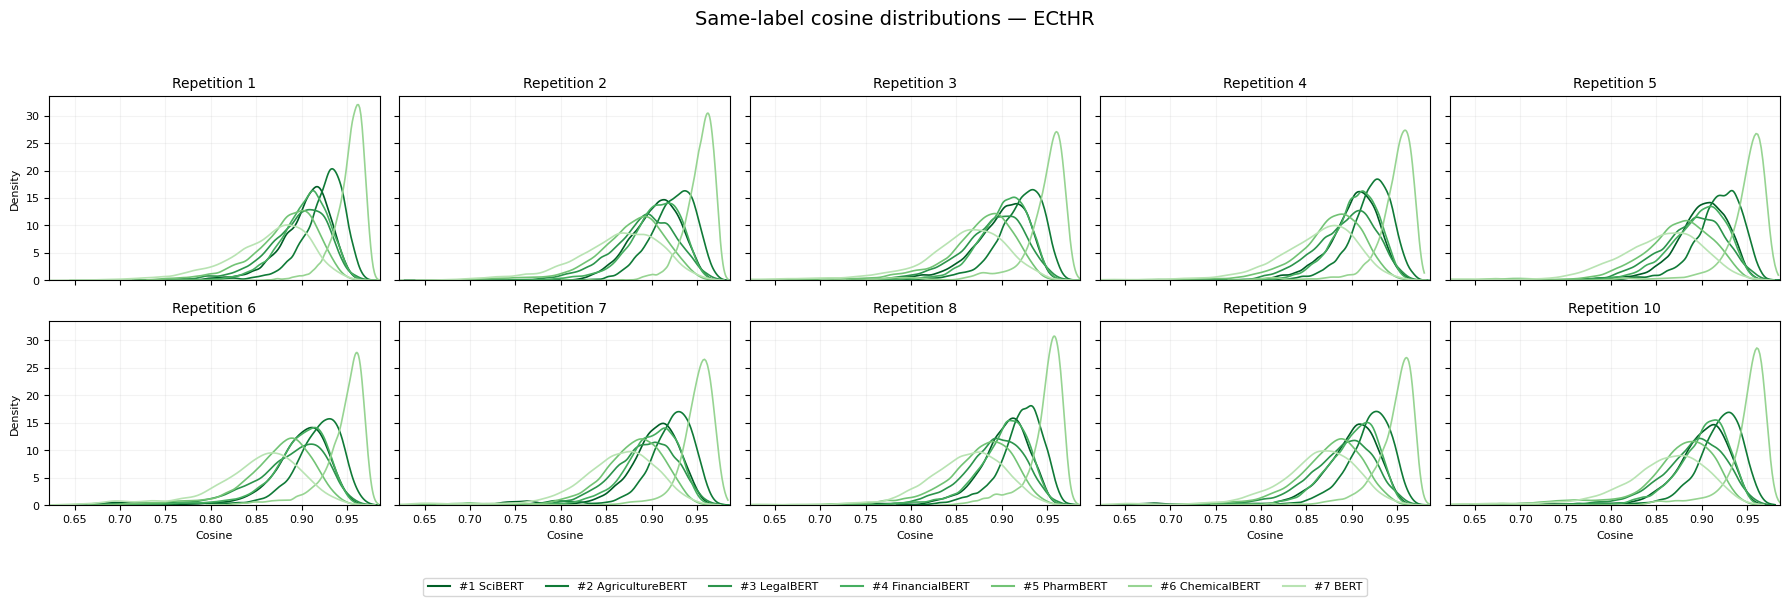

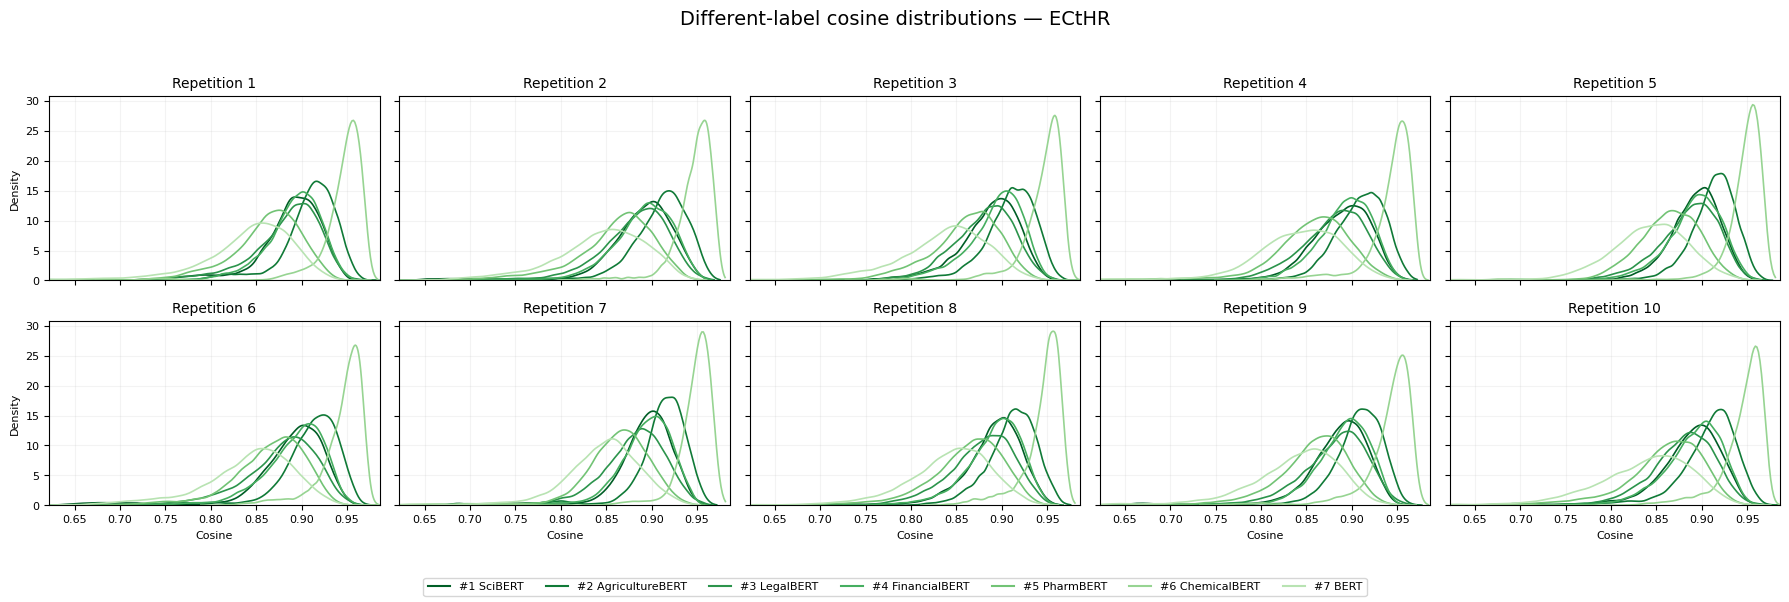

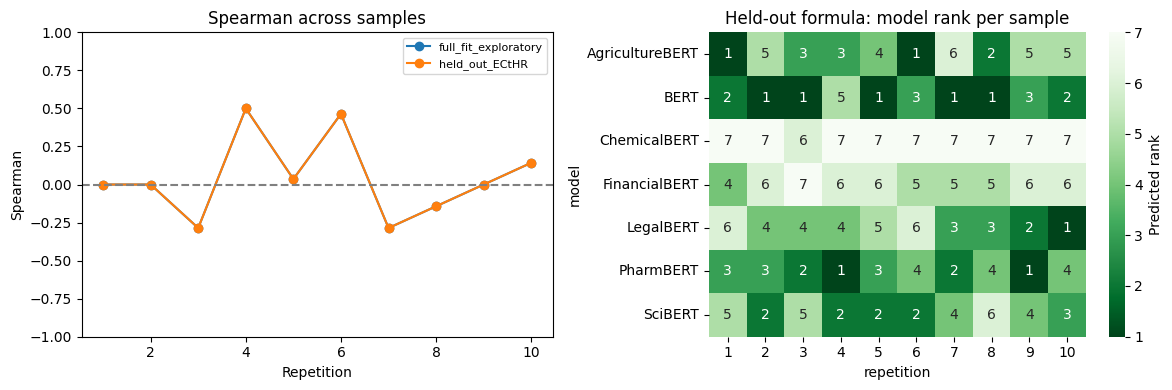

COMPLETED: 10 repetitions, 70 model runs. Results: /home/amyliu/Desktop/GR/ECtHR/results/uncertainty10_gpu_20261025_170358


In [30]:
from matplotlib.lines import Line2D
name_to_checkpoint = {v:k for k,v in MODEL_NAMES.items()}
real_ranks = dict(zip(order, actual))
colors = {name:plt.cm.Greens(np.interp(real_ranks[name],[1,7],[.92,.30])) for name in order}
all_scores = np.concatenate([np.asarray(result[key],dtype=float)
    for result in results["full_results"].values() for key in ["same_scores","diff_scores_original"]])
xmin = max(-1, np.quantile(all_scores,.001)-.01)
xmax = min(1, np.quantile(all_scores,.999)+.01)
for key, title, filename in [
    ("same_scores","Same-label cosine distributions","same_label_all_10_repetitions.png"),
    ("diff_scores_original","Different-label cosine distributions","different_label_all_10_repetitions.png")]:
    fig, axes = plt.subplots(2,5,figsize=(18,6),sharex=True,sharey=True)
    for rep, ax in enumerate(axes.flat,start=1):
        for name in sorted(order,key=real_ranks.get):
            values = np.asarray(results["full_results"][(rep,name_to_checkpoint[name])][key],dtype=float)
            sns.kdeplot(x=values,ax=ax,color=colors[name],bw_adjust=.8,clip=(-1,1),cut=0,linewidth=1.2)
        ax.set_title(f"Repetition {rep}",fontsize=10)
        ax.set_xlim(xmin,xmax);ax.set_xlabel("Cosine",fontsize=8);ax.set_ylabel("Density",fontsize=8)
        ax.tick_params(labelsize=8);ax.grid(alpha=.15)
    fig.suptitle(title+" — ECtHR",fontsize=14)
    fig.legend(handles=[Line2D([0],[0],color=colors[name],label=f"#{int(real_ranks[name])} {name}")
        for name in sorted(order,key=real_ranks.get)],loc="lower center",ncol=7,fontsize=8)
    fig.tight_layout(rect=[0,.07,1,.95])
    fig.savefig(OUTPUT_DIR / filename,dpi=180,bbox_inches="tight")
    plt.show();plt.close(fig)
fig, axes=plt.subplots(1,2,figsize=(12,4))
for procedure,g in round_df.groupby("procedure"):
    axes[0].plot(g.repetition,g.spearman,marker="o",label=procedure)
axes[0].axhline(0,color="gray",linestyle="--");axes[0].set_ylim(-1,1)
axes[0].set(xlabel="Repetition",ylabel="Spearman",title="Spearman across samples");axes[0].legend(fontsize=8)
rank_matrix=score_df.query('procedure == "held_out_ECtHR"').pivot(index="model",columns="repetition",values="predicted_rank")
sns.heatmap(rank_matrix,annot=True,fmt=".0f",cmap="Greens_r",vmin=1,vmax=7,ax=axes[1],cbar_kws={"label":"Predicted rank"})
axes[1].set_title("Held-out formula: model rank per sample")
fig.tight_layout();fig.savefig(OUTPUT_DIR / "combination_stability.png",dpi=180,bbox_inches="tight")
plt.show();plt.close(fig)
print("COMPLETED: 10 repetitions, 70 model runs. Results:", OUTPUT_DIR.resolve())
